# EDA

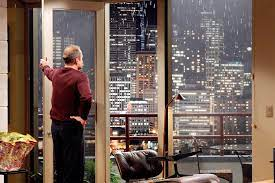

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

In [2]:
df_amy = pd.read_csv("data/eda.csv")
df_amy.head()

,sale_id,date,price,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,1,2014-10-13,221900.000,7129300520,3.000,1.000,1180.000,5650.000,1.000,NaN,...,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,2,2014-12-09,538000.000,6414100192,3.000,2.250,2570.000,7242.000,2.000,0.000,...,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,3,2015-02-25,180000.000,5631500400,2.000,1.000,770.000,10000.000,1.000,0.000,...,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,4,2014-12-09,604000.000,2487200875,4.000,3.000,1960.000,5000.000,1.000,0.000,...,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,5,2015-02-18,510000.000,1954400510,3.000,2.000,1680.000,8080.000,1.000,0.000,...,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


In [3]:
print(df_amy.shape)
df_amy.info()

(21597, 22)
<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sale_id        21597 non-null  int64  
 1   date           21597 non-null  str    
 2   price          21597 non-null  float64
 3   id             21597 non-null  int64  
 4   bedrooms       21597 non-null  float64
 5   bathrooms      21597 non-null  float64
 6   sqft_living    21597 non-null  float64
 7   sqft_lot       21597 non-null  float64
 8   floors         21597 non-null  float64
 9   waterfront     19206 non-null  float64
 10  view           21534 non-null  float64
 11  condition      21597 non-null  int64  
 12  grade          21597 non-null  int64  
 13  sqft_above     21597 non-null  float64
 14  sqft_basement  21145 non-null  float64
 15  yr_built       21597 non-null  int64  
 16  yr_renovated   17749 non-null  float64
 17  zipcode        21597 non-null  int64  
 18  lat  

In [4]:
df_amy["date"] = pd.to_datetime(df_amy["date"])
df_amy.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_id        21597 non-null  int64         
 1   date           21597 non-null  datetime64[us]
 2   price          21597 non-null  float64       
 3   id             21597 non-null  int64         
 4   bedrooms       21597 non-null  float64       
 5   bathrooms      21597 non-null  float64       
 6   sqft_living    21597 non-null  float64       
 7   sqft_lot       21597 non-null  float64       
 8   floors         21597 non-null  float64       
 9   waterfront     19206 non-null  float64       
 10  view           21534 non-null  float64       
 11  condition      21597 non-null  int64         
 12  grade          21597 non-null  int64         
 13  sqft_above     21597 non-null  float64       
 14  sqft_basement  21145 non-null  float64       
 15  yr_built       21597 non-null 

In [5]:
missing_values = df_amy.isna().sum()
print(missing_values)

sale_id             0
date                0
price               0
id                  0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       2391
view               63
condition           0
grade               0
sqft_above          0
sqft_basement     452
yr_built            0
yr_renovated     3848
zipcode             0
lat                 0
long                0
sqft_living15       0
sqft_lot15          0
dtype: int64


In [6]:
missing_values_percentage = (missing_values / len(df_amy) * 100).round(2)
print(missing_values_percentage)

sale_id          0.000
date             0.000
price            0.000
id               0.000
bedrooms         0.000
bathrooms        0.000
sqft_living      0.000
sqft_lot         0.000
floors           0.000
waterfront      11.070
view             0.290
condition        0.000
grade            0.000
sqft_above       0.000
sqft_basement    2.090
yr_built         0.000
yr_renovated    17.820
zipcode          0.000
lat              0.000
long             0.000
sqft_living15    0.000
sqft_lot15       0.000
dtype: float64


In [7]:
pd.DataFrame({"fehlende Werte": missing_values, "Prozent": missing_values_percentage}).query("`fehlende Werte` > 0")

,fehlende Werte,Prozent
waterfront,2391,11.070
view,63,0.290
sqft_basement,452,2.090
yr_renovated,3848,17.820


In [8]:
print(df_amy.duplicated().sum())
print(df_amy["id"].duplicated().sum())
df_amy.describe().T

0
177


,count,mean,min,25%,50%,75%,max,std
sale_id,21597.000,10799.000,1.000,5400.000,10799.000,16198.000,21597.000,6234.661
date,21597,2014-10-29 04:20:38.171968,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,21597.000,540296.574,78000.000,322000.000,450000.000,645000.000,7700000.000,367368.140
id,21597.000,4580474287.771,1000102.000,2123049175.000,3904930410.000,7308900490.000,9900000190.000,2876735715.748
bedrooms,21597.000,3.373,1.000,3.000,3.000,4.000,33.000,0.926
bathrooms,21597.000,2.116,0.500,1.750,2.250,2.500,8.000,0.769
sqft_living,21597.000,2080.322,370.000,1430.000,1910.000,2550.000,13540.000,918.106
sqft_lot,21597.000,15099.409,520.000,5040.000,7618.000,10685.000,1651359.000,41412.637
floors,21597.000,1.494,1.000,1.000,1.500,2.000,3.500,0.540
waterfront,19206.000,0.008,0.000,0.000,0.000,0.000,1.000,0.087


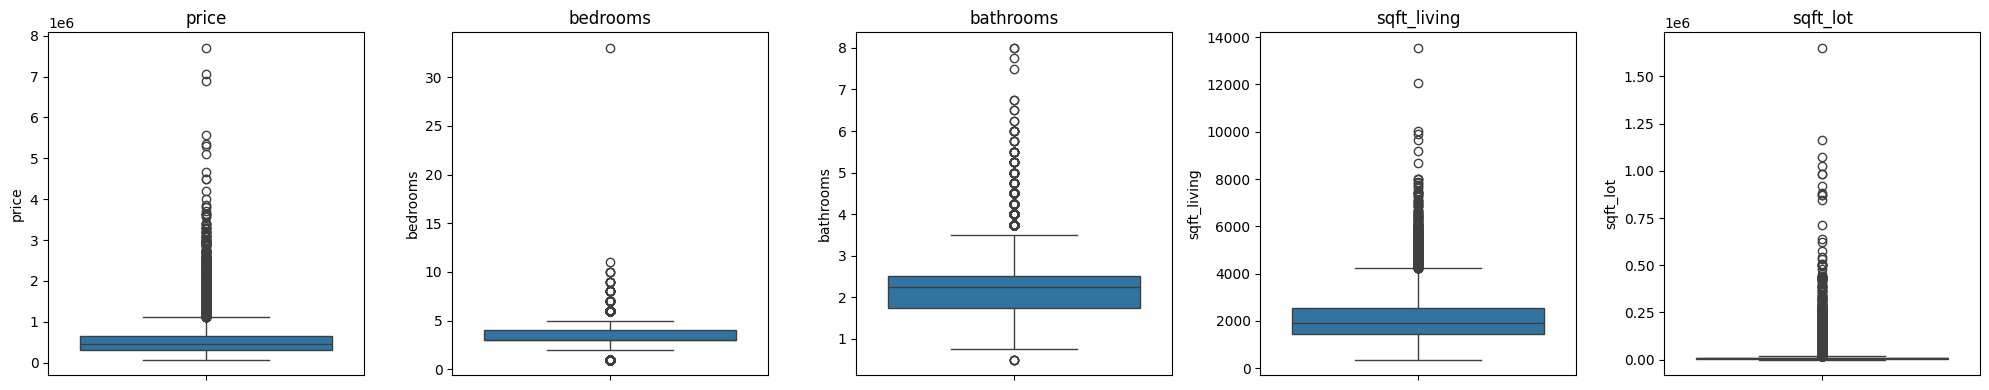

In [9]:
# Ausreiser visualisieren
cols = ["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot"]
fig, axes = plt.subplots(1, len(cols), figsize=(20, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df_amy[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()    

In [10]:
# Ausreisser zaehlen
def count_outliers(s):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

df_amy[cols].apply(count_outliers)    

price          1158
bedrooms        530
bathrooms       561
sqft_living     571
sqft_lot       2419
dtype: int64

In [11]:
df_amy.describe().T

,count,mean,min,25%,50%,75%,max,std
sale_id,21597.000,10799.000,1.000,5400.000,10799.000,16198.000,21597.000,6234.661
date,21597,2014-10-29 04:20:38.171968,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,21597.000,540296.574,78000.000,322000.000,450000.000,645000.000,7700000.000,367368.140
id,21597.000,4580474287.771,1000102.000,2123049175.000,3904930410.000,7308900490.000,9900000190.000,2876735715.748
bedrooms,21597.000,3.373,1.000,3.000,3.000,4.000,33.000,0.926
bathrooms,21597.000,2.116,0.500,1.750,2.250,2.500,8.000,0.769
sqft_living,21597.000,2080.322,370.000,1430.000,1910.000,2550.000,13540.000,918.106
sqft_lot,21597.000,15099.409,520.000,5040.000,7618.000,10685.000,1651359.000,41412.637
floors,21597.000,1.494,1.000,1.000,1.500,2.000,3.500,0.540
waterfront,19206.000,0.008,0.000,0.000,0.000,0.000,1.000,0.087


In [12]:
df_amy = df_amy.rename(columns={"id": "house_id"})
df_amy.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_id        21597 non-null  int64         
 1   date           21597 non-null  datetime64[us]
 2   price          21597 non-null  float64       
 3   house_id       21597 non-null  int64         
 4   bedrooms       21597 non-null  float64       
 5   bathrooms      21597 non-null  float64       
 6   sqft_living    21597 non-null  float64       
 7   sqft_lot       21597 non-null  float64       
 8   floors         21597 non-null  float64       
 9   waterfront     19206 non-null  float64       
 10  view           21534 non-null  float64       
 11  condition      21597 non-null  int64         
 12  grade          21597 non-null  int64         
 13  sqft_above     21597 non-null  float64       
 14  sqft_basement  21145 non-null  float64       
 15  yr_built       21597 non-null 

In [13]:
df_amy["sqft_basement"] = df_amy["sqft_basement"].fillna(df_amy["sqft_living"] - df_amy["sqft_above"])
# Rohwerte sind mit Faktor 10 gespeichert (19910 = 1991); nur teilen, wenn noch nicht geschehen,
# damit die Zelle mehrfach ausgefuehrt werden kann
yr = df_amy["yr_renovated"].fillna(0)
df_amy["yr_renovated"] = np.where(yr > 3000, yr / 10, yr).astype(int)
df_amy["waterfront"] = df_amy["waterfront"].fillna(0).astype(int)
df_amy["view"] = df_amy["view"].fillna(0).astype(int)

print(df_amy.isna().sum().sum())
df_amy.loc[df_amy["yr_renovated"] > 0, "yr_renovated"].describe()

0


count    744.000
mean    1995.929
std       15.600
min     1934.000
25%     1987.000
50%     2000.000
75%     2007.250
max     2015.000
Name: yr_renovated, dtype: float64

In [14]:
df_amy.loc[df_amy["bedrooms"] > 10, ["price", "bedrooms", "bathrooms", "sqft_living", "grade"]]
df_amy.loc[df_amy["bedrooms"]== 33, "bedrooms"] = 3

887000.0


Text(0.5, 0, 'log10(Preis)')

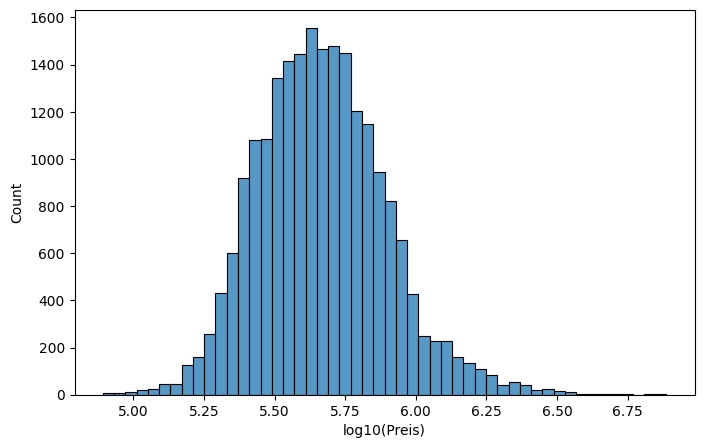

In [15]:
# Grenze fuer Top10 % Häuser festlegen
top_10_percent_price = df_amy["price"].quantile(0.9)
print(top_10_percent_price)
df_amy["top10"] = df_amy["price"] >= top_10_percent_price
# Visualisierung top10
sns.histplot(np.log10(df_amy["price"]), bins=50)
plt.xlabel("log10(Preis)")

In [16]:
# Entfernung zum Stadtzentrum berechnen
def haversine_km(lat1, long1, lat2, long2):
    R = 6371  # Erdradius in km 
    lat1, long1, lat2, long2 = map(np.radians, [lat1, long1, lat2, long2])
    dlat = lat2 - lat1
    dlon = long2 - long1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

CENTER_LAT, CENTER_LON = 47.6062, -122.3321
df_amy["dist_center_km"] = haversine_km(df_amy["lat"], df_amy["long"], CENTER_LAT, CENTER_LON)

print(haversine_km(47.6062, -122.3321, 47.6101, -122.2015))  # erwartet: ca. 9,8
df_amy["dist_center_km"].describe()
# minimum liegt nahe 0 also Haeuser in der Naehe des Stadtzentrums, maximum liegt bei ca. 50 km,
# was darauf hindeutet, dass einige Haeuser in den Vororten oder sogar ausserhalb der Stadtgrenzen liegen.

9.800330649918818


count   21597.000
mean       18.451
std        10.637
min         0.983
25%         9.783
50%        16.504
75%        25.261
max        77.094
Name: dist_center_km, dtype: float64

In [17]:
# lege Zonen für meine Hypothesen fest
q25, q75 = df_amy["dist_center_km"].quantile([0.25, 0.75])
df_amy["lage"] = np.select(
    [df_amy["dist_center_km"] <= q25, df_amy["dist_center_km"] >= q75],
    ["zentral", "randlage"],
    default="mittel"
)
df_amy["lage"].value_counts()

lage
mittel      10797
randlage     5400
zentral      5400
Name: count, dtype: int64

In [18]:
SQFT_TO_M2 = 0.092903

sqft_cols = [c for c in df_amy.columns if c.startswith("sqft_")]
for col in sqft_cols:
    df_amy[col.replace("sqft_", "m2_")] = (df_amy[col] * SQFT_TO_M2).round(1)

df_amy["price_per_m2"] = df_amy["price"] / df_amy["m2_living"]

df_amy[["sqft_living", "m2_living", "sqft_lot", "m2_lot"]].describe().T

df_amy = df_amy.drop(columns=sqft_cols)

Text(0, 0.5, 'Preis pro m2 ($)')

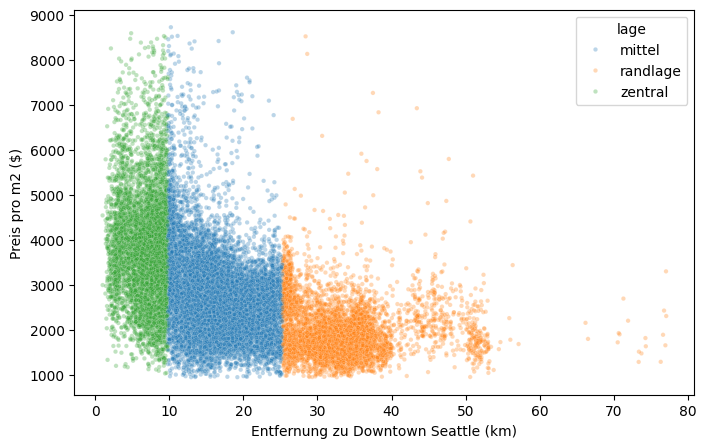

In [19]:
# Scatterplot zeigt sofort ob der Preis mit der Entfernung zum Stadtzentrum sinkt. 
sns.scatterplot(data=df_amy, x="dist_center_km", y="price_per_m2", hue="lage", alpha=0.3, s=10)
plt.xlabel("Entfernung zu Downtown Seattle (km)")
plt.ylabel("Preis pro m2 ($)")

<Axes: >

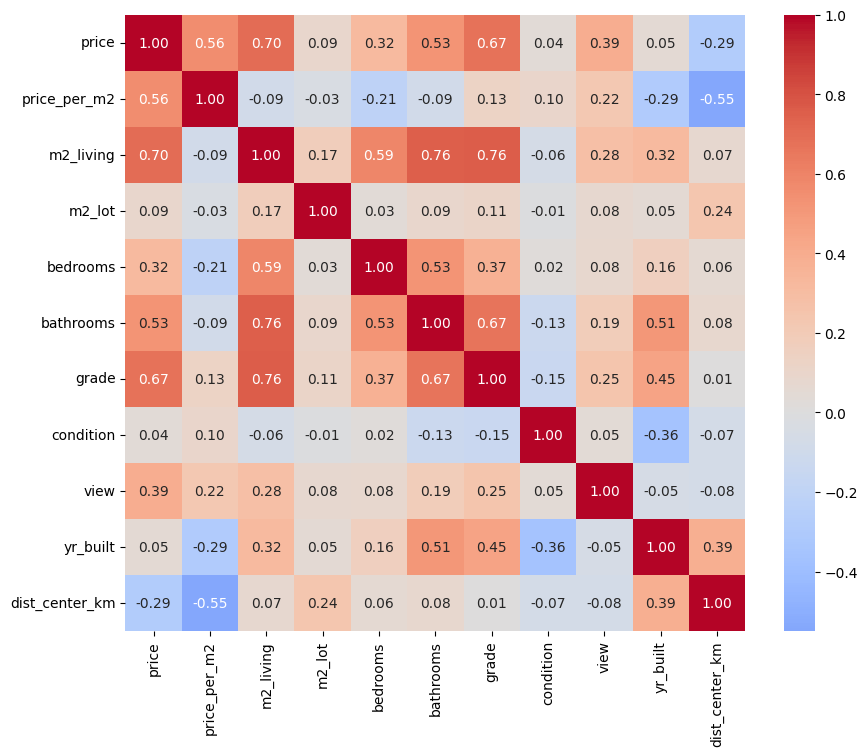

In [20]:
# überblick über alle Zusammenhänge zwischen den Variablen

num_cols = ["price", "price_per_m2", "m2_living", "m2_lot", "bedrooms", "bathrooms",
            "grade", "condition", "view", "yr_built", "dist_center_km"]
plt.figure(figsize=(10, 8))
sns.heatmap(df_amy[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)

Text(0, 0.5, 'Median Preis pro m² ($)')

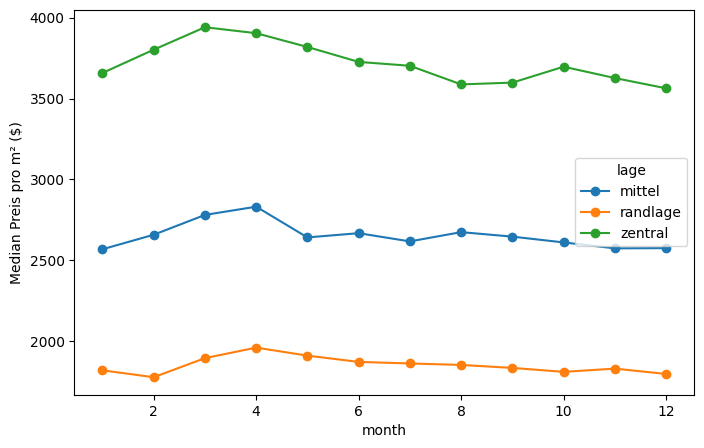

In [21]:
# relevant fuer H1 Preis pro Monat getrennt nach Lage - Multivariate Analyse

df_amy["month"] = df_amy["date"].dt.month
monthly = df_amy.groupby(["month", "lage"])["price_per_m2"].median().unstack()
monthly.plot(marker="o")
plt.ylabel("Median Preis pro m² ($)")

In [22]:
# H1 Kennzahlen je Jahreszeit
from scipy import stats

season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Fruehling", 4: "Fruehling", 5: "Fruehling",
              6: "Sommer", 7: "Sommer", 8: "Sommer",
              9: "Herbst", 10: "Herbst", 11: "Herbst"}
df_amy["season"] = df_amy["month"].map(season_map)

season_stats = df_amy.groupby("season").agg(
    anzahl=("price", "size"),
    median_preis=("price", "median"),
    median_preis_m2=("price_per_m2", "median"),
).loc[["Fruehling", "Sommer", "Herbst", "Winter"]]
print(season_stats.round(0))

fruehling = df_amy.loc[df_amy["season"] == "Fruehling", "price_per_m2"]
winter = df_amy.loc[df_amy["season"] == "Winter", "price_per_m2"]
print("Mann-Whitney Fruehling vs. Winter:", stats.mannwhitneyu(fruehling, winter))
print("Zeitraum der Daten:", df_amy["date"].min().date(), "bis", df_amy["date"].max().date())


           anzahl  median_preis  median_preis_m2
season                                          
Fruehling    6518    465000.000         2721.000
Sommer       6328    455000.000         2643.000
Herbst       5056    443725.000         2607.000
Winter       3695    430000.000         2526.000
Mann-Whitney Fruehling vs. Winter: MannwhitneyuResult(statistic=np.float64(13193250.0), pvalue=np.float64(8.929960953637395e-16))
Zeitraum der Daten: 2014-05-02 bis 2015-05-27


### Ergebnis H1 (Gesamtmarkt) – bestätigt, kleiner Effekt

- Im **Frühling** ist der Median-Preis pro m² am höchsten (ca. 2.720 \$), im **Winter** am niedrigsten (ca. 2.530 \$) → ca. **8 % Unterschied**.
- Spitzenmonat ist der **April**, am günstigsten sind **Dezember/Januar**.
- Das Muster zeigt sich in allen drei Lagen (zentral, mittel, Randlage), der Unterschied ist statistisch signifikant (Mann-Whitney, p < 0,001).
- **Einschränkung:** Die Daten decken nur ein Jahr ab (Mai 2014 – Mai 2015). Saisoneffekt und allgemeiner Markttrend lassen sich daher nicht sauber trennen.
- → Für Amys Segmente getrennt betrachtet im Abschnitt **Timing für Amy** weiter unten.


renoviert
False    817
True     123
Name: count, dtype: int64

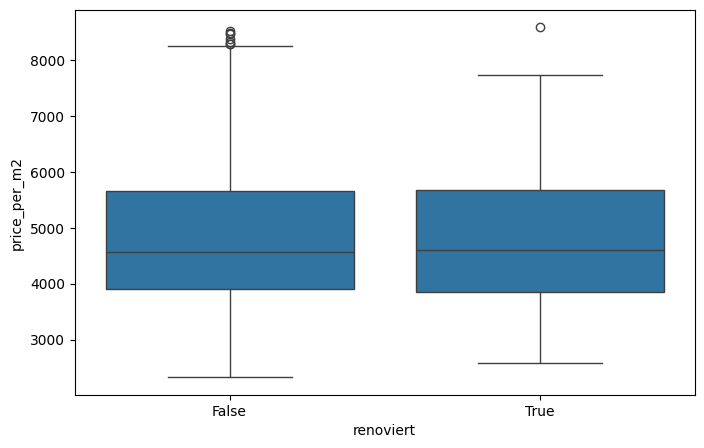

In [23]:
# relevant fuer H2 renovierte und nicht renovierte Häuser im Top Segment - Multivariate Analyse

df_amy["renoviert"] = df_amy["yr_renovated"] > 0
top_central = df_amy[df_amy["top10"] & (df_amy["lage"] == "zentral")]
sns.boxplot(data=top_central, x="renoviert", y="price_per_m2")

top_central["renoviert"].value_counts()

In [24]:
# H2 renoviert vs. nicht renoviert – gesamt, Top-Segment zentral und nur alte Haeuser
def ren_stats(d):
    return d.groupby("renoviert").agg(
        anzahl=("price", "size"),
        median_preis=("price", "median"),
        median_preis_m2=("price_per_m2", "median"),
        median_baujahr=("yr_built", "median"),
        median_grade=("grade", "median"),
    ).round(0)

print("Gesamt:"); print(ren_stats(df_amy))
print("\nTop 10 % zentral:"); print(ren_stats(top_central))
print("\nBaujahr < 1960:"); print(ren_stats(df_amy[df_amy["yr_built"] < 1960]))
print("\nMann-Whitney Top 10 % zentral:",
      stats.mannwhitneyu(top_central.loc[top_central["renoviert"], "price_per_m2"],
                         top_central.loc[~top_central["renoviert"], "price_per_m2"]))


Gesamt:
           anzahl  median_preis  median_preis_m2  median_baujahr  median_grade
renoviert                                                                     
False       20853    449000.000         2618.000        1976.000         7.000
True          744    607502.000         3246.000        1942.000         8.000

Top 10 % zentral:
           anzahl  median_preis  median_preis_m2  median_baujahr  median_grade
renoviert                                                                     
False         817   1250000.000         4558.000        1955.000         9.000
True          123   1280000.000         4610.000        1941.000         9.000

Baujahr < 1960:
           anzahl  median_preis  median_preis_m2  median_baujahr  median_grade
renoviert                                                                     
False        6785    435000.000         3173.000        1943.000         7.000
True          600    603000.000         3325.000        1933.000         7.000

Mann-Wh

### Ergebnis H2 – im einfachen Vergleich nicht bestätigt

- Über alle Häuser erzielen renovierte Häuser zwar einen höheren Preis pro m² (ca. 3.250 \$ vs. 2.620 \$), sie sind aber im Schnitt **deutlich älter** (Baujahr-Median 1942) und haben einen **höheren Grade** – der Aufpreis lässt sich nicht sauber der Renovierung zuordnen.
- Im **Top-Segment zentral** gibt es praktisch **keinen Unterschied** (ca. 4.610 \$ vs. 4.560 \$ pro m², p ≈ 0,96).
- Nur 744 Häuser (3,4 %) sind überhaupt renoviert.
- **Gewinn ist mit diesen Daten nicht messbar:** Es fehlen Renovierungskosten und Preise vor/nach der Renovierung desselben Hauses.
- → Aussage: *Renovierte Häuser erzielen tendenziell höhere Preise, ein Gewinn durch Renovierung lässt sich aber nicht nachweisen.*
- → Genauer untersucht in **Vertiefung 1 und 2** weiter unten.


In [25]:
# H3 Definition von Durchschnittshaus
# es liegt weder am Wasser und hat auch keine Aussicht und Preis und WOhnfläche jeweils im mittleren Bereich.

def in_median(s):
    q25, q75 = s.quantile([0.25, 0.75])
    return s.between(q25, q75)

df_amy["durchschnittshaus"] = (
    (df_amy["waterfront"] == 0) &
    (df_amy["view"] == 0) &
    in_median(df_amy["price"]) &
    in_median(df_amy["m2_living"]) & 
    in_median(df_amy["grade"]) & 
    in_median(df_amy["condition"])
)

df_amy["versteck"] = df_amy["durchschnittshaus"] & (df_amy["lage"] == "randlage")
print(df_amy["versteck"].sum(), "Durchschnittshäuser in Randlage")


1032 Durchschnittshäuser in Randlage


In [26]:
# H3 eine Karte mit den Durchschnittshäusern in Randlage erstellen
v = df_amy[df_amy["versteck"]]
fig = px.scatter_map(
    v,
    lat="lat", lon="long", color="zipcode",
    hover_data=["price", "m2_living", "grade", "dist_center_km"],
    zoom=8, height=650, map_style="open-street-map"
)
fig.show()

Text(0, 0.5, 'Postleitzahl')

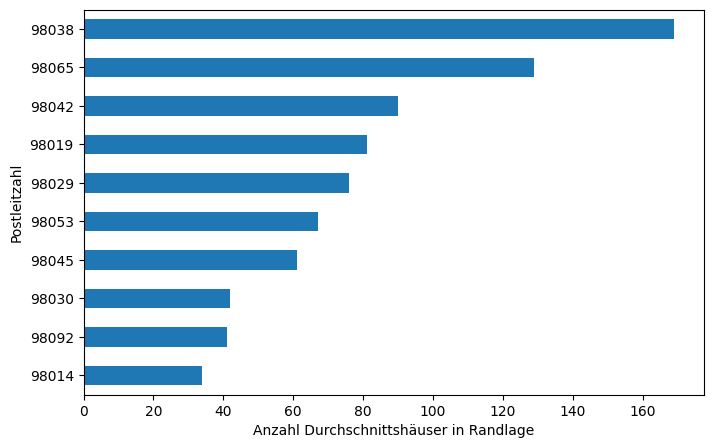

In [27]:
# H3 PLZ mit den meisten Versteck Häusern

zip_stats = df_amy.groupby("zipcode").agg(
    haeuser_gesamt=("house_id", "size"),
    versteck_anzahl=("versteck", "sum"),
    versteck_anteil=("versteck", "mean"),
    median_preis=("price", "median"),
    median_preis_m2=("price_per_m2", "median"),
    median_dist_km=("dist_center_km", "median"),
)

top_zips = (zip_stats[zip_stats["versteck_anzahl"] > 0]
            .sort_values("versteck_anzahl", ascending=False)
            .head(10))
top_zips["versteck_anteil"] = (top_zips["versteck_anteil"] * 100).round(1)
top_zips.round(0)


top_zips["versteck_anzahl"].sort_values().plot(kind="barh")
plt.xlabel("Anzahl Durchschnittshäuser in Randlage")
plt.ylabel("Postleitzahl")

# 98038 ist Maple Valley , 98065 ist Snoqualmie und 98042 ist Covington

In [28]:
# H3 Anteil der Durchschnittshaeuser an allen Haeusern je PLZ (wo faellt man am wenigsten auf?)
ortsnamen = {98038: "Maple Valley", 98065: "Snoqualmie", 98042: "Covington", 98019: "Duvall",
             98029: "Issaquah", 98053: "Redmond", 98045: "North Bend", 98030: "Kent",
             98092: "Auburn", 98014: "Carnation"}
orte = top_zips.copy()
orte["ort"] = orte.index.map(ortsnamen)
orte[["ort", "haeuser_gesamt", "versteck_anzahl", "versteck_anteil", "median_preis_m2", "median_dist_km"]] \
    .sort_values("versteck_anteil", ascending=False).round(1)


,ort,haeuser_gesamt,versteck_anzahl,versteck_anteil,median_preis_m2,median_dist_km
zipcode,,,,,,
98019,Duvall,190,81,42.600,2123.100,30.800
98065,Snoqualmie,308,129,41.900,2221.000,35.700
98038,Maple Valley,589,169,28.700,1839.900,34.900
98045,North Bend,220,61,27.700,2255.500,45.600
98014,Carnation,124,34,27.400,2283.400,32.500
98029,Issaquah,321,76,23.700,2922.500,25.300
98053,Redmond,403,67,16.600,2891.000,25.200
98042,Covington,547,90,16.500,1714.000,31.400
98030,Kent,256,42,16.400,1638.100,28.500


### Ergebnis Orte

- In **Duvall (98019)** und **Snoqualmie (98065)** sind über **40 %** aller Häuser Durchschnittshäuser – deutlich mehr als im Schnitt der Randlage (ca. 19 %). Dort fällt Amy am wenigsten auf.
- **Maple Valley (98038)** hat die meisten Durchschnittshäuser (169) und damit die größte Auswahl.
- Der Preis pro m² liegt in diesen Orten rund **40–55 % unter dem Zentrum** (ca. 3.720 \$/m²).


In [29]:
# H3 Preise je Lage, Korrelation mit der Entfernung und Anteil Durchschnittshaeuser je Lage
lage_stats = df_amy.groupby("lage").agg(
    anzahl=("price", "size"),
    median_preis=("price", "median"),
    median_preis_m2=("price_per_m2", "median"),
    median_m2=("m2_living", "median"),
    anteil_durchschnitt=("durchschnittshaus", "mean"),
).loc[["zentral", "mittel", "randlage"]]
lage_stats["anteil_durchschnitt"] = (lage_stats["anteil_durchschnitt"] * 100).round(1)
print(lage_stats.round(1))

print("\nSpearman Entfernung ~ Preis:     ", round(df_amy["dist_center_km"].corr(df_amy["price"], method="spearman"), 2))
print("Spearman Entfernung ~ Preis/m2:  ", round(df_amy["dist_center_km"].corr(df_amy["price_per_m2"], method="spearman"), 2))

# Nord/Sued-Vergleich, da die Entfernung allein nicht alles erklaert
df_amy["nord_sued"] = np.where(df_amy["lat"] >= CENTER_LAT, "Nord", "Sued")
print(df_amy.groupby(["nord_sued", "lage"])["price_per_m2"].median().unstack().round(0))


          anzahl  median_preis  median_preis_m2  median_m2  \
lage                                                         
zentral     5400    557655.000         3719.200    157.400   
mittel     10797    464950.000         2655.500    184.900   
randlage    5400    327000.000         1856.100    183.000   

          anteil_durchschnitt  
lage                           
zentral                19.700  
mittel                 27.600  
randlage               19.100  

Spearman Entfernung ~ Preis:      -0.35
Spearman Entfernung ~ Preis/m2:   -0.62
lage        mittel  randlage  zentral
nord_sued                            
Nord      2855.000  2469.000 4127.000
Sued      2324.000  1800.000 3116.000


### Ergebnis H3 – Preisteil bestätigt, „unauffällig“ nicht bestätigt

- Mit zunehmender Entfernung zum Zentrum sinkt der Preis deutlich: Median **558.000 \$ zentral** vs. **327.000 \$ in Randlage**; pro m² ca. **3.720 \$ vs. 1.860 \$** – also etwa die Hälfte, bei gleicher oder größerer Wohnfläche.
- Spearman-Korrelation Entfernung ~ Preis/m² ≈ **−0,62** → stärkster Zusammenhang der drei Hypothesen.
- Aber: **Nord/Süd** spielt eine große Rolle – Randlage im Norden ist deutlich teurer als im Süden. Die Entfernung ist nicht der einzige Preisfaktor.
- **„Unauffällig“** ist über das Durchschnittshaus definiert (kein Wasser, keine Aussicht, Preis/Fläche/Grade/Zustand im mittleren Bereich). Der Anteil dieser Häuser ist in der **Randlage (ca. 19 %) nicht höher** als im Zentrum (ca. 20 %) und sogar niedriger als in der mittleren Lage (ca. 28 %). Man wohnt in Randlage also nicht automatisch „unauffälliger“.
- Es gibt aber gezielt PLZ mit vielen Versteck-Häusern: **98038 Maple Valley, 98065 Snoqualmie und 98042 Covington**.


## Timing für Amy (H1)

Getrennte Betrachtung der beiden Segmente, die für Amy relevant sind. Steht nach H3, weil die Durchschnittshäuser in Randlage dort definiert werden.


In [30]:
# H1 fuer Amy: Saison im Verkaufssegment (Top 10 % zentral) und im Kaufsegment (Durchschnittshaus Randlage)
season_order = ["Fruehling", "Sommer", "Herbst", "Winter"]

def season_stats_for(d):
    return d.groupby("season").agg(
        anzahl=("price", "size"),
        median_preis=("price", "median"),
        median_preis_m2=("price_per_m2", "median"),
    ).loc[season_order].round(0)

top_central_all = df_amy[df_amy["top10"] & (df_amy["lage"] == "zentral")]
print("Verkauf – Top 10 % zentral:")
print(season_stats_for(top_central_all))
print("\nKauf – Durchschnittshaeuser in Randlage:")
print(season_stats_for(df_amy[df_amy["versteck"]]))


Verkauf – Top 10 % zentral:
           anzahl  median_preis  median_preis_m2
season                                          
Fruehling     323   1220000.000         4719.000
Sommer        277   1270000.000         4521.000
Herbst        204   1255000.000         4406.000
Winter        136   1295000.000         4765.000

Kauf – Durchschnittshaeuser in Randlage:
           anzahl  median_preis  median_preis_m2
season                                          
Fruehling     320    399950.000         2184.000
Sommer        317    395000.000         2134.000
Herbst        229    390000.000         2095.000
Winter        166    366200.000         2031.000


### Ergebnis H1 für Amy – teilweise bestätigt

- **Verkauf (Top 10 % zentral):** Es gibt **keinen Frühlingsaufschlag**. Winter (ca. 4.770 \$/m²) und Frühling (ca. 4.720 \$/m²) liegen gleichauf, nur der **Herbst** ist schwächer (ca. 4.410 \$/m², rund 7 % weniger). Im teuren Segment bestimmt die Lage den Preis, nicht die Jahreszeit.
- **Kauf (Durchschnittshäuser in Randlage):** Im **Winter** ist der Median-Kaufpreis am niedrigsten (ca. 366.000 \$ statt 400.000 \$ im Frühling, ca. 8 % günstiger).
- → „Im Winter kaufen“ stimmt für Amy, „im Frühling verkaufen“ nicht: Für ihre Top-Häuser ist nur der Herbst zu meiden.
- **Einschränkung:** Kleine Gruppen (Top 10 % zentral im Winter: nur 136 Verkäufe).


## Vertiefung 1 – Wiederverkäufe (H2)

176 Häuser wurden im Datenzeitraum zweimal verkauft. Ein Preissprung deutlich über der Marktentwicklung im selben Zeitraum deutet auf „kaufen → renovieren → teurer verkaufen“ hin. Das kommt einer direkten Gewinnmessung am nächsten.


In [31]:
# H2 Wiederverkaeufe: Preisanstieg je Haus vs. Marktentwicklung im selben Zeitraum
rep = df_amy[df_amy["house_id"].duplicated(keep=False)].sort_values(["house_id", "date"])
flips = rep.groupby("house_id").agg(
    preis_1=("price", "first"),
    preis_2=("price", "last"),
    datum_1=("date", "first"),
    datum_2=("date", "last"),
    lage=("lage", "first"),
    yr_built=("yr_built", "first"),
)
flips["gewinn_pct"] = (flips["preis_2"] / flips["preis_1"] - 1) * 100
flips["tage"] = (flips["datum_2"] - flips["datum_1"]).dt.days

# Marktindex: Median Preis pro m2 je Kalendermonat
markt = df_amy.groupby(df_amy["date"].dt.to_period("M"))["price_per_m2"].median()
flips["markt_pct"] = (markt.loc[flips["datum_2"].dt.to_period("M")].values
                      / markt.loc[flips["datum_1"].dt.to_period("M")].values - 1) * 100
flips["ueber_markt_pct"] = flips["gewinn_pct"] - flips["markt_pct"]

print(flips[["gewinn_pct", "markt_pct", "ueber_markt_pct", "tage"]].describe().round(1))
print("\nAnteil mit Gewinn:      ", round((flips["gewinn_pct"] > 0).mean() * 100, 1), "%")
print("Anteil mit > 20 % Gewinn:", round((flips["gewinn_pct"] > 20).mean() * 100, 1), "%")
print("\nMedian Baujahr Wiederverkaeufe:", flips["yr_built"].median(), "| alle Haeuser:", df_amy["yr_built"].median())
print("Median Kaufpreis Wiederverkaeufe:", flips["preis_1"].median(), "| alle Haeuser:", df_amy["price"].median())
print(flips.groupby(pd.cut(flips["tage"], [0, 90, 180, 270, 400]))["gewinn_pct"].agg(["size", "median"]).round(1))


       gewinn_pct  markt_pct  ueber_markt_pct    tage
count     176.000    176.000          176.000 176.000
mean       56.800      2.000           54.800 183.300
std        46.700      5.200           46.800  67.000
min        -5.400     -6.100          -15.400  61.000
25%        23.600     -3.000           20.700 128.500
50%        54.400      3.000           52.900 177.500
75%        74.200      6.200           72.200 233.800
max       321.800     11.400          317.300 315.000

Anteil mit Gewinn:       94.9 %
Anteil mit > 20 % Gewinn: 76.1 %

Median Baujahr Wiederverkaeufe: 1959.0 | alle Haeuser: 1975.0
Median Kaufpreis Wiederverkaeufe: 261500.0 | alle Haeuser: 450000.0
            size  median
tage                    
(0, 90]       13  23.800
(90, 180]     77  59.300
(180, 270]    65  56.500
(270, 400]    21  28.000


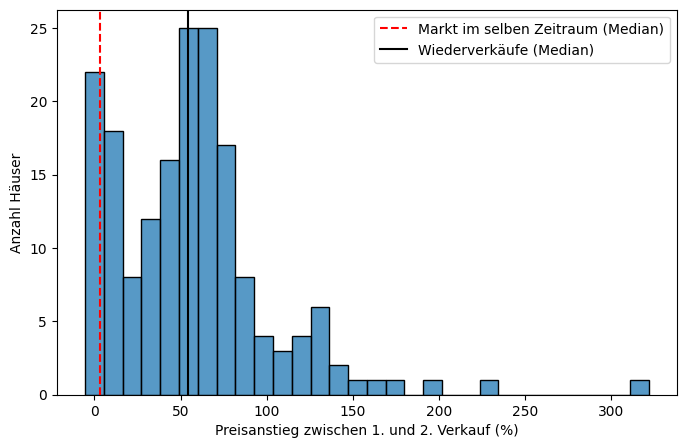

In [32]:
# Verteilung Preisanstieg der Wiederverkaeufe vs. Marktentwicklung
sns.histplot(flips["gewinn_pct"], bins=30)
plt.axvline(flips["markt_pct"].median(), color="red", linestyle="--", label="Markt im selben Zeitraum (Median)")
plt.axvline(flips["gewinn_pct"].median(), color="black", label="Wiederverkäufe (Median)")
plt.xlabel("Preisanstieg zwischen 1. und 2. Verkauf (%)")
plt.ylabel("Anzahl Häuser")
plt.legend()


### Ergebnis Wiederverkäufe

- Median-Preisanstieg **ca. +54 % nach rund 6 Monaten**, der Markt stieg im selben Zeitraum nur um **ca. +3 %**.
- **95 %** der Häuser wurden mit Gewinn wiederverkauft, **76 %** mit mehr als 20 %.
- Die Häuser sind **älter** (Baujahr-Median 1959 vs. 1975) und beim Kauf **deutlich günstiger** (ca. 262.000 \$ vs. 450.000 \$) – typisches Muster für Renovierungsobjekte („Flips“).
- **Einschränkung:** Die Hausmerkmale (`condition`, `grade`, `yr_renovated`) sind bei beiden Verkäufen identisch – der Datensatz ist eine Momentaufnahme. Dass renoviert wurde, ist naheliegend, aber nicht belegt; die Renovierungskosten sind unbekannt.


## Vertiefung 2 – Korrelationen je Hypothese

Wie stark hängen die Variablen der drei Hypothesen mit dem Preis zusammen? Verwendet wird die **Spearman-Korrelation** (robust gegenüber Ausreißern und schiefen Preisverteilungen). Zusätzlich wird geprüft, ob die Zusammenhänge durch andere Merkmale (Größe, Grade, Baujahr) erklärt werden könnten.


,price,price_per_m2,m2_living,grade,yr_built
H1 Fruehling (vs. Winter),0.064,0.080,0.001,0.010,-0.008
H2 renoviert,0.095,0.088,0.048,0.016,-0.195
H3 Entfernung (km),-0.353,-0.622,0.139,0.045,0.396


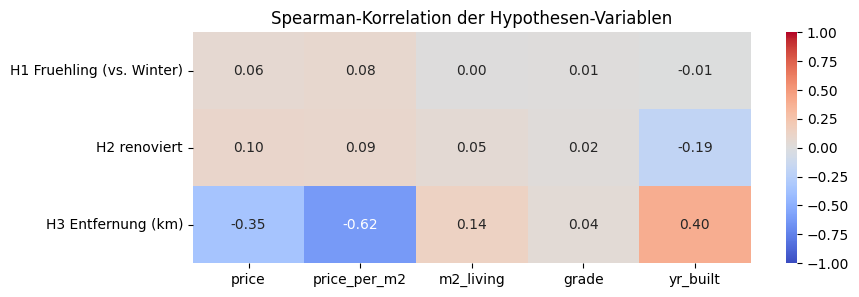

In [33]:
# Hypothesen-Variablen als 0/1 kodieren
df_amy["fruehling"] = (df_amy["season"] == "Fruehling").astype(int)
df_amy["renoviert_int"] = df_amy["renoviert"].astype(int)

# H1 nur Fruehling vs. Winter vergleichen
fw = df_amy[df_amy["season"].isin(["Fruehling", "Winter"])]

korr_cols = ["price", "price_per_m2", "m2_living", "grade", "yr_built"]
korrelationen = pd.DataFrame({
    "H1 Fruehling (vs. Winter)": fw[["fruehling"] + korr_cols].corr(method="spearman")["fruehling"],
    "H2 renoviert": df_amy[["renoviert_int"] + korr_cols].corr(method="spearman")["renoviert_int"],
    "H3 Entfernung (km)": df_amy[["dist_center_km"] + korr_cols].corr(method="spearman")["dist_center_km"],
}).loc[korr_cols].T

plt.figure(figsize=(9, 3))
sns.heatmap(korrelationen, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman-Korrelation der Hypothesen-Variablen")
korrelationen.round(3)


In [34]:
# H3 Korrelation Entfernung ~ Preis/m2 getrennt nach Nord und Sued
for richtung, gruppe in df_amy.groupby("nord_sued"):
    r = gruppe["dist_center_km"].corr(gruppe["price_per_m2"], method="spearman")
    print(f"{richtung}: r = {r:.2f}")

# H2 Korrelation renoviert ~ Preis/m2 innerhalb gleicher Bauqualitaet (grade)
ren_grade = df_amy.groupby("grade").apply(lambda g: pd.Series({
    "anzahl_renoviert": g["renoviert"].sum(),
    "r_renoviert_preis_m2": g["renoviert_int"].corr(g["price_per_m2"], method="spearman"),
    "median_m2_nicht_ren": g.loc[~g["renoviert"], "price_per_m2"].median(),
    "median_m2_renoviert": g.loc[g["renoviert"], "price_per_m2"].median(),
}))
ren_grade = ren_grade[ren_grade["anzahl_renoviert"] >= 30]
ren_grade["aufpreis_pct"] = (ren_grade["median_m2_renoviert"] / ren_grade["median_m2_nicht_ren"] - 1) * 100
ren_grade.round(2)


Nord: r = -0.63
Sued: r = -0.51


,anzahl_renoviert,r_renoviert_preis_m2,median_m2_nicht_ren,median_m2_renoviert,aufpreis_pct
grade,,,,,
6,73.000,-0.060,2603.980,2216.150,-14.890
7,276.000,0.050,2446.210,2933.100,19.900
8,220.000,0.130,2640.760,3422.500,29.600
9,111.000,0.190,2710.080,3777.150,39.370
10,41.000,0.220,2898.310,4849.880,67.330


### Ergebnis Korrelationen

| Hypothese | Korrelation mit Preis/m² | Stärke |
|---|---|---|
| H1 Frühling (vs. Winter) | r ≈ **+0,08** | sehr schwach, aber gleichgerichtet |
| H2 renoviert | r ≈ **+0,09** | sehr schwach |
| H3 Entfernung zum Zentrum | r ≈ **−0,62** | stark |

- **H1:** Frühling korreliert praktisch nicht mit Wohnfläche oder Grade (r ≈ 0). Der höhere Frühlingspreis liegt also **nicht** daran, dass im Frühling größere oder bessere Häuser verkauft werden. Der Effekt ist echt, aber klein.
- **H2:** Insgesamt kaum Zusammenhang. Renovierte Häuser sind deutlich älter (r ≈ −0,2 mit Baujahr). **Innerhalb gleicher Bauqualität** zeigt sich aber ein Muster: Bei Grade 6 erzielen renovierte Häuser sogar weniger (ca. −15 %), ab **Grade 7** mehr – und der Aufpreis wächst mit der Qualität (Grade 7: ca. +20 %, Grade 8: ca. +30 %, Grade 9: ca. +39 %, Grade 10: ca. +67 % pro m², jeweils Median). Renovierung lohnt sich also eher bei hochwertigeren Häusern.
- **H3:** Stärkster Zusammenhang aller Hypothesen. Er gilt im Norden (r ≈ −0,63) und im Süden (r ≈ −0,51), ist also kein Effekt einer einzelnen Region. Größere Entfernung geht nur schwach mit größerer Wohnfläche einher (r ≈ 0,14).
- **Hinweis:** Korrelation ist keine Kausalität. Andere Einflüsse (z. B. Markttrend über das Jahr) können nicht ausgeschlossen werden.


## Fazit

| Hypothese | Ergebnis |
|---|---|
| **H1** Im Frühling verkaufen, im Winter kaufen | ⚠️ teilweise – Gesamtmarkt: Frühling ca. 8 % teurer als Winter (r ≈ 0,08). Für Amys Top-Häuser im Zentrum gibt es aber keinen Frühlingsaufschlag, nur der Herbst ist ca. 7 % schwächer. Kaufen im Winter: ca. 8 % günstiger. Daten nur über ein Jahr |
| **H2** Renovierung steigert den Gewinn | ⚠️ teilweise – insgesamt kaum Zusammenhang (r ≈ 0,09), ab Grade 7 aber deutlicher Aufpreis (ca. +20 % bis +67 % pro m²); im Top-Segment zentral kein Unterschied (ca. +1 %); Wiederverkäufe +54 % in 6 Monaten (Markt +3 %); Renovierungskosten unbekannt |
| **H3** Weiter weg vom Zentrum = günstiger und unauffälliger | ⚠️ teilweise – günstiger klar bestätigt (r ≈ −0,62, Preis/m² in Randlage halbiert); unauffälliger nicht generell, aber in einzelnen Orten (Duvall, Snoqualmie: über 40 % Durchschnittshäuser) |

## Empfehlungen für Amy Williams

1. **Herbst meiden:** Top-Häuser im Zentrum gestaffelt im Winter oder Frühling verkaufen – im Herbst (Sep–Nov) erzielen sie ca. 7 % weniger pro m².
2. **Nicht renovieren:** Vor dem Verkauf der zentralen Top-Häuser nicht renovieren – kein messbarer Aufpreis in diesem Segment.
3. **Im Winter kaufen:** Durchschnittshäuser am Stadtrand im Winter kaufen – ca. 8 % günstiger als im Frühling (Median 366.000 \$ statt 400.000 \$).
4. **Snoqualmie & Duvall:** Dort ist mehr als jedes dritte Haus ein Durchschnittshaus. Für mehr Auswahl: Maple Valley.
